# Demografía, construcción y precio de la vivienda

¿Crece la demanda de vivienda más rápido que la oferta? ¿Qué parte del crecimiento de residentes procede de la migración?

Este bloque contrasta afirmaciones descriptivas habituales: **se construye poco**, **la población crece más rápido que las viviendas** y **el crecimiento poblacional procede principalmente de la inmigración**. No parte de que sean ciertas, ni atribuye las declaraciones a políticos concretos sin una cita verificable.

Se reutiliza la **tasación media anual de vivienda libre en €/m²** del notebook 1. El objetivo es 2000–2025; la comparación conjunta empieza en **2001**, primer año del parque publicado. Las otras fuentes conservan su cobertura real.

In [1]:
from pathlib import Path
import sys
from IPython.display import display, Image

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT / "src"))
from spain_housing.demographics import run_analysis

panels, findings = run_analysis(ROOT)
def show(*names):
    for name in names:
        display(Image(filename=str(ROOT / "reports/figures/block02" / f"{name}.png")))


## Población y viviendas totales en España

Número de habitantes y de viviendas por año, en cifras absolutas y con un mismo eje desde cero. Periodo común disponible: **2001–2025**.

El parque cuenta todas las viviendas existentes: ocupadas, secundarias y vacías. No mide las viviendas anunciadas en venta o alquiler. La población al cierre de 2025 es provisional.

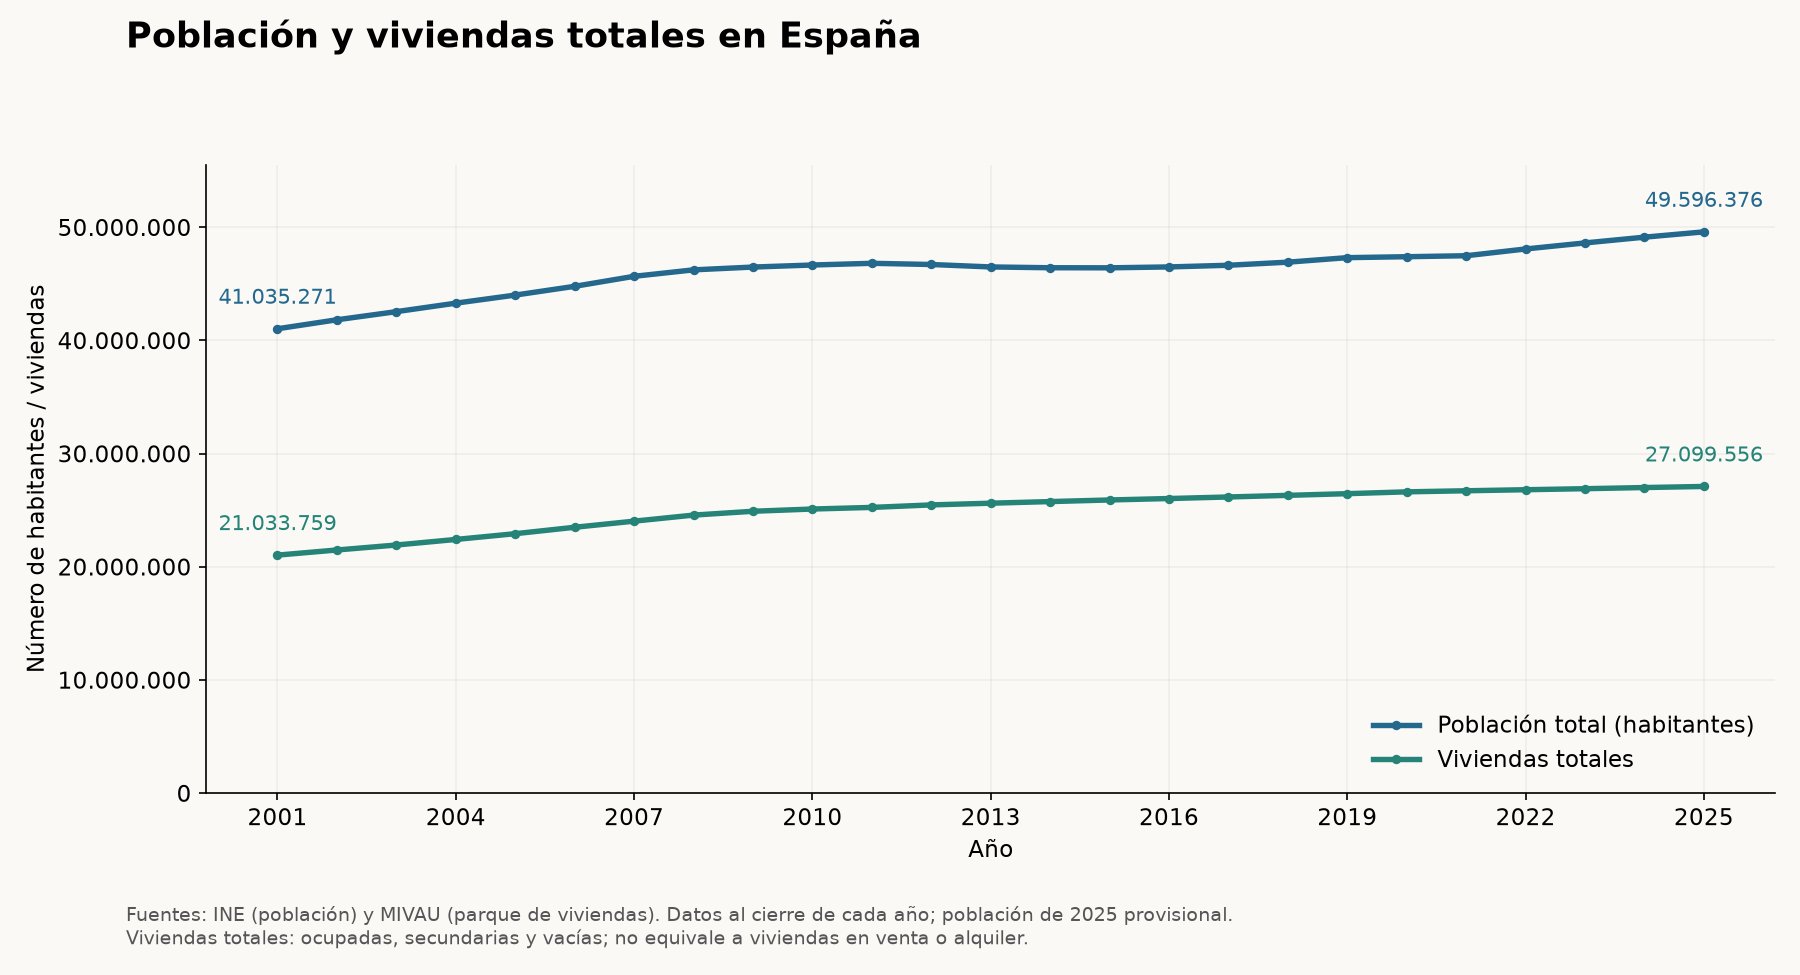

In [2]:
show('01_price_population_stock')

## Población y viviendas principales y no principales

La misma población y el mismo parque total de la gráfica anterior, añadiendo el desglose anual **2001–2025** de MIVAU:

- **Principales:** se usan como residencia habitual.
- **No principales:** resto del parque, incluidas segundas residencias y viviendas vacías.

Principales + no principales = viviendas totales. Este desglose **no identifica viviendas inhabitables ni viviendas disponibles para comprar o alquilar**.

[Fuente MIVAU: estimación del parque de viviendas](https://datos.gob.es/es/catalogo/e05233601-estimacion-del-parque-de-viviendas1).


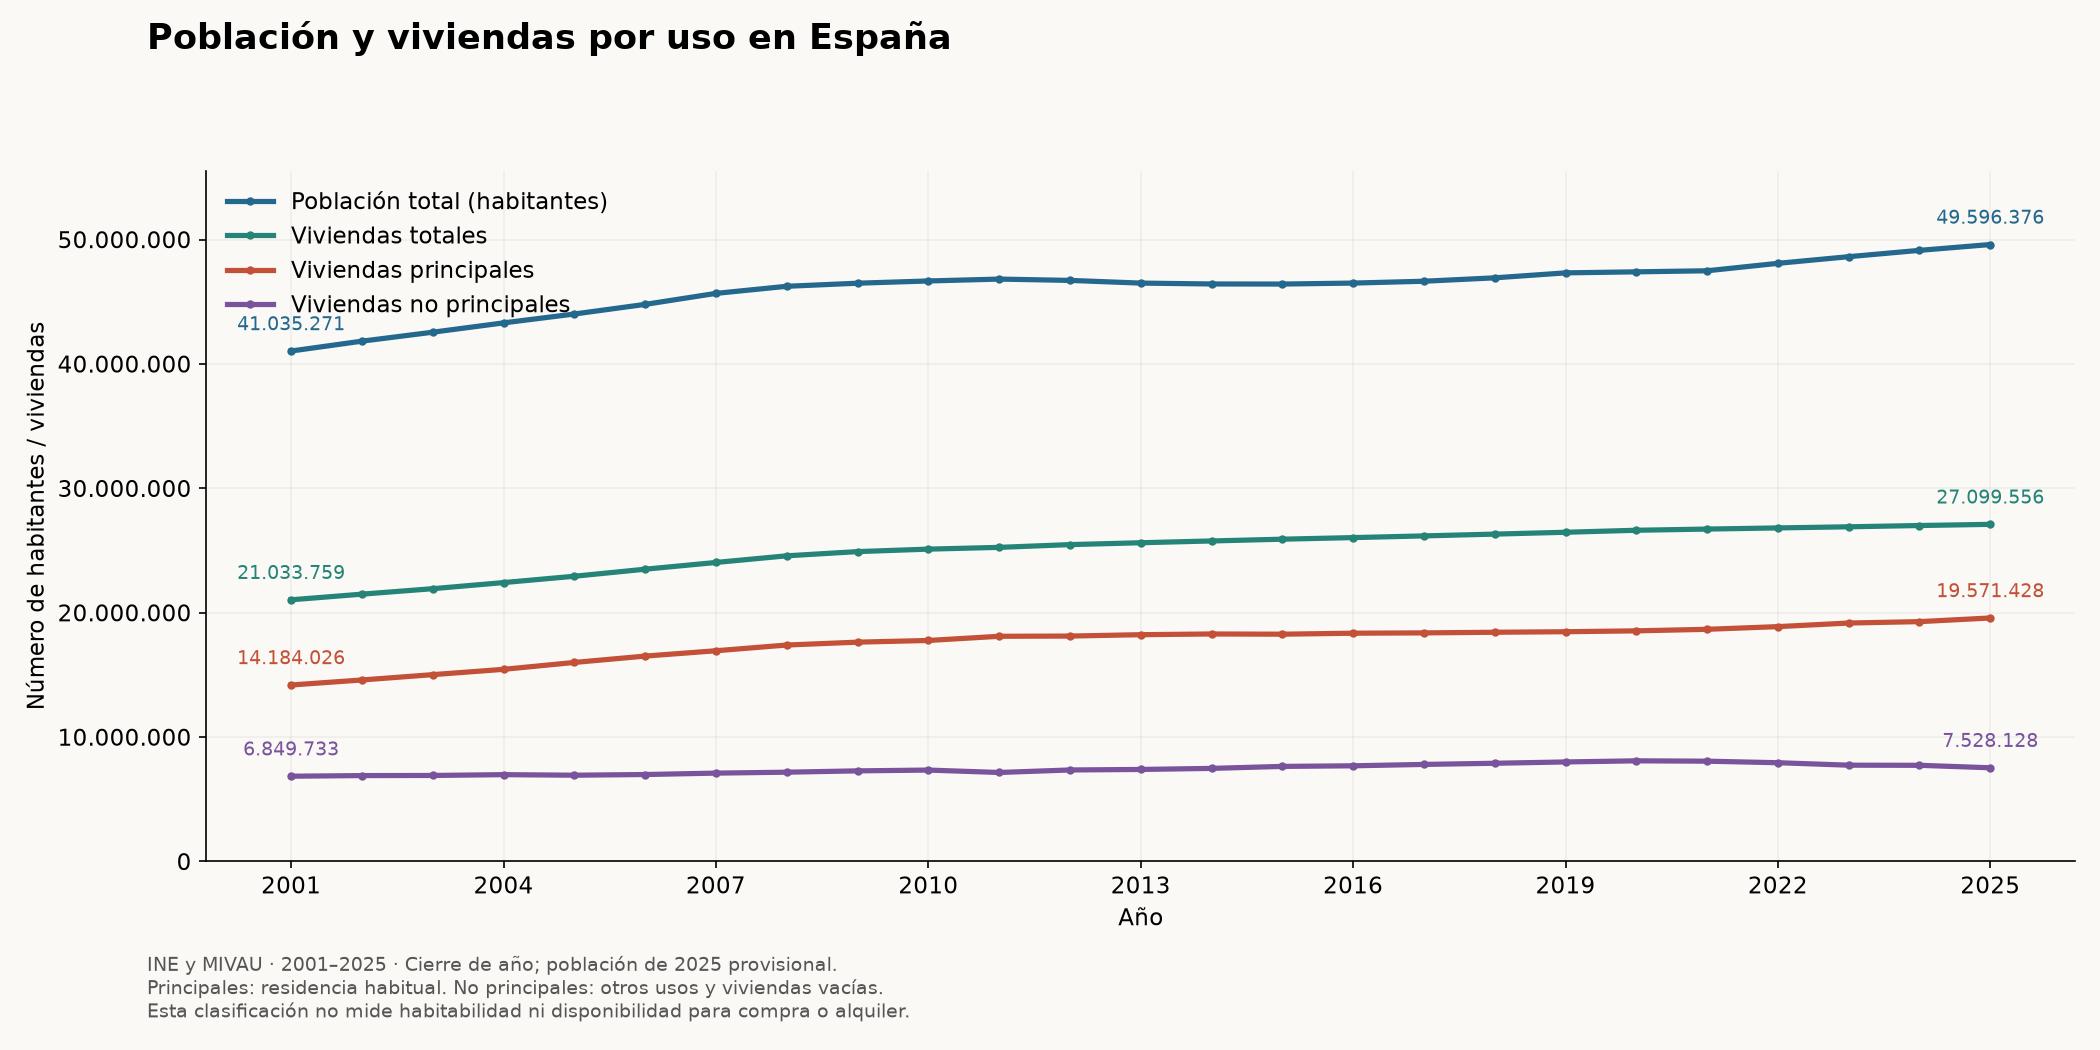

In [3]:
show('11_population_dwelling_use')

## Viviendas por habitante y por adulto

Las ratios separan el tamaño del parque del crecimiento poblacional. Se muestran en paneles distintos con unidades explícitas y ejes desde cero.

Una caída reciente puede coexistir con una mejora desde 2001. Una ratio nacional tampoco identifica si las viviendas se encuentran donde hay demanda.

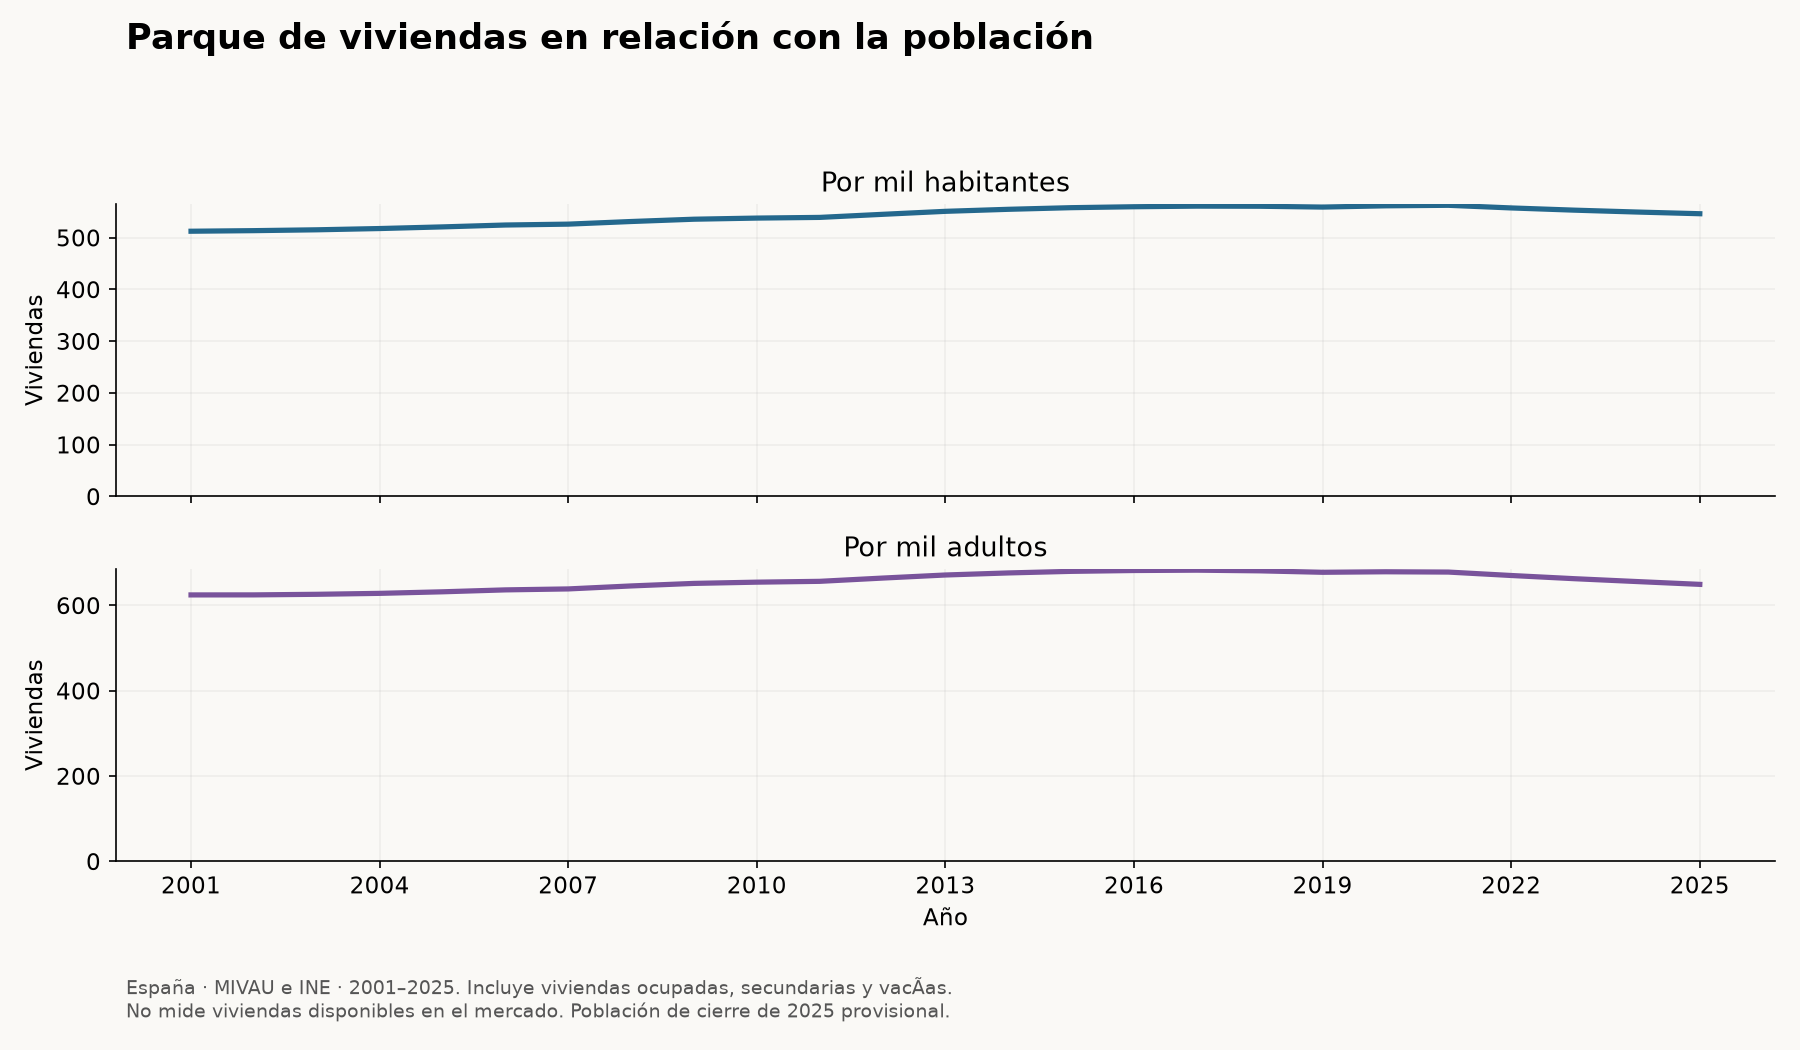

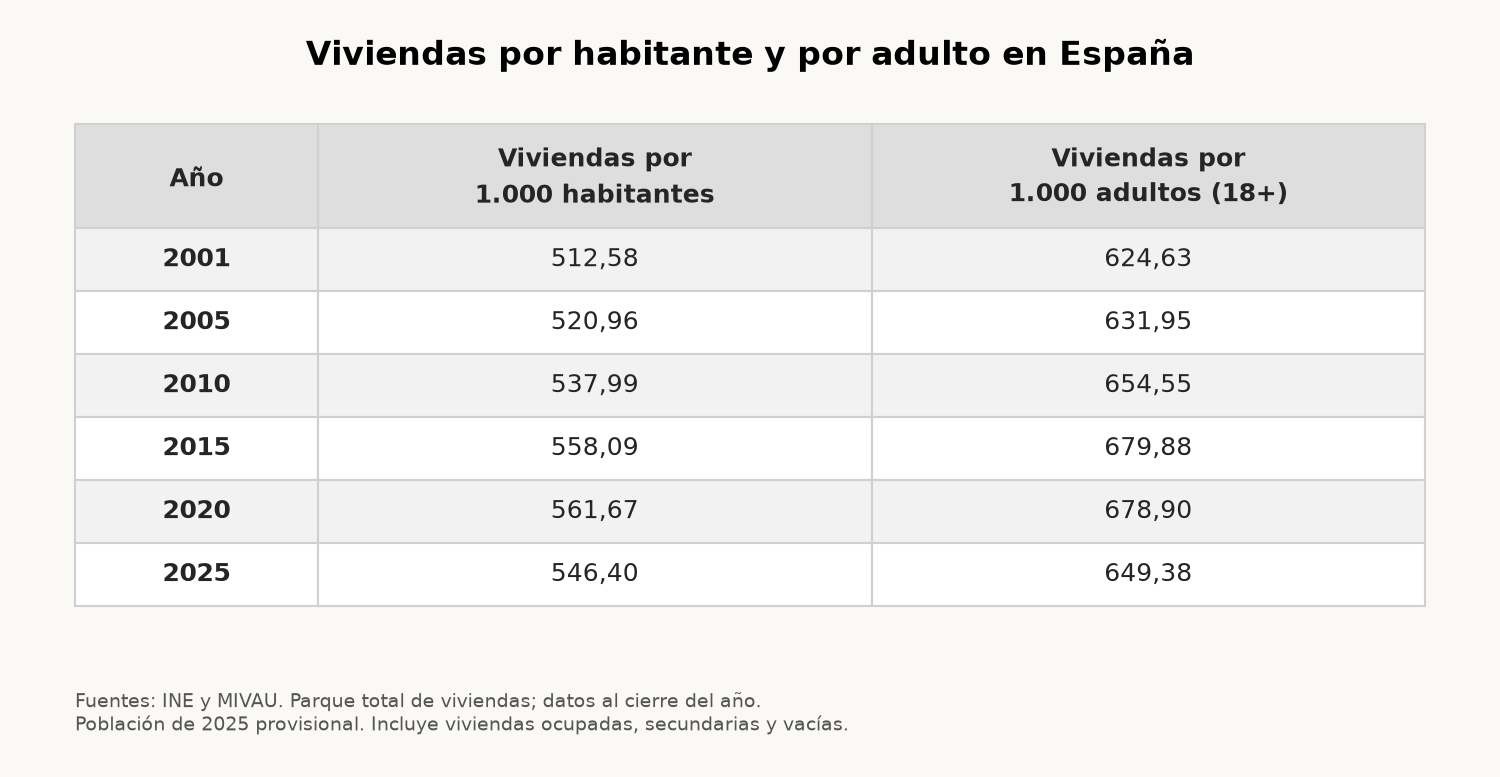

In [4]:
show('02_dwellings_per_resident', '02_ratios_table')

## Viviendas y hogares en España

Totales anuales de viviendas y hogares, **2001–2025**. Los hogares proceden de las estadísticas demográficas del **INE**, sin utilizar la EPA:

- Censos de 2001 y 2011 (noviembre).
- Encuesta Continua de Hogares (ECH), 2013–2019, con referencia a enero del año siguiente.
- Estadística Continua de Población (ECP), 2020–2025, con referencia a enero del año siguiente; los datos recientes son provisionales.

**2002–2010 y 2012 son estimaciones propias**, por interpolación lineal entre los datos oficiales más cercanos. Se representan con puntos huecos y trazos discontinuos. No son cifras del INE ni permiten conocer la evolución real dentro de esos intervalos. No se extrapola una tendencia reciente hacia el pasado. Los cambios de operación y fecha de referencia limitan la comparabilidad.

Las viviendas totales de MIVAU incluyen secundarias y vacías: la diferencia entre ambas líneas no mide viviendas disponibles.

Fuentes: [Censos](https://www.ine.es/prensa/np824.pdf), [ECH](https://www.ine.es/dyngs/INEbase/operacion.htm?c=Estadistica_C&cid=1254736176952&idp=1254735572981), [ECP](https://www.ine.es/dyngs/Prensa/ECP2T26.htm).


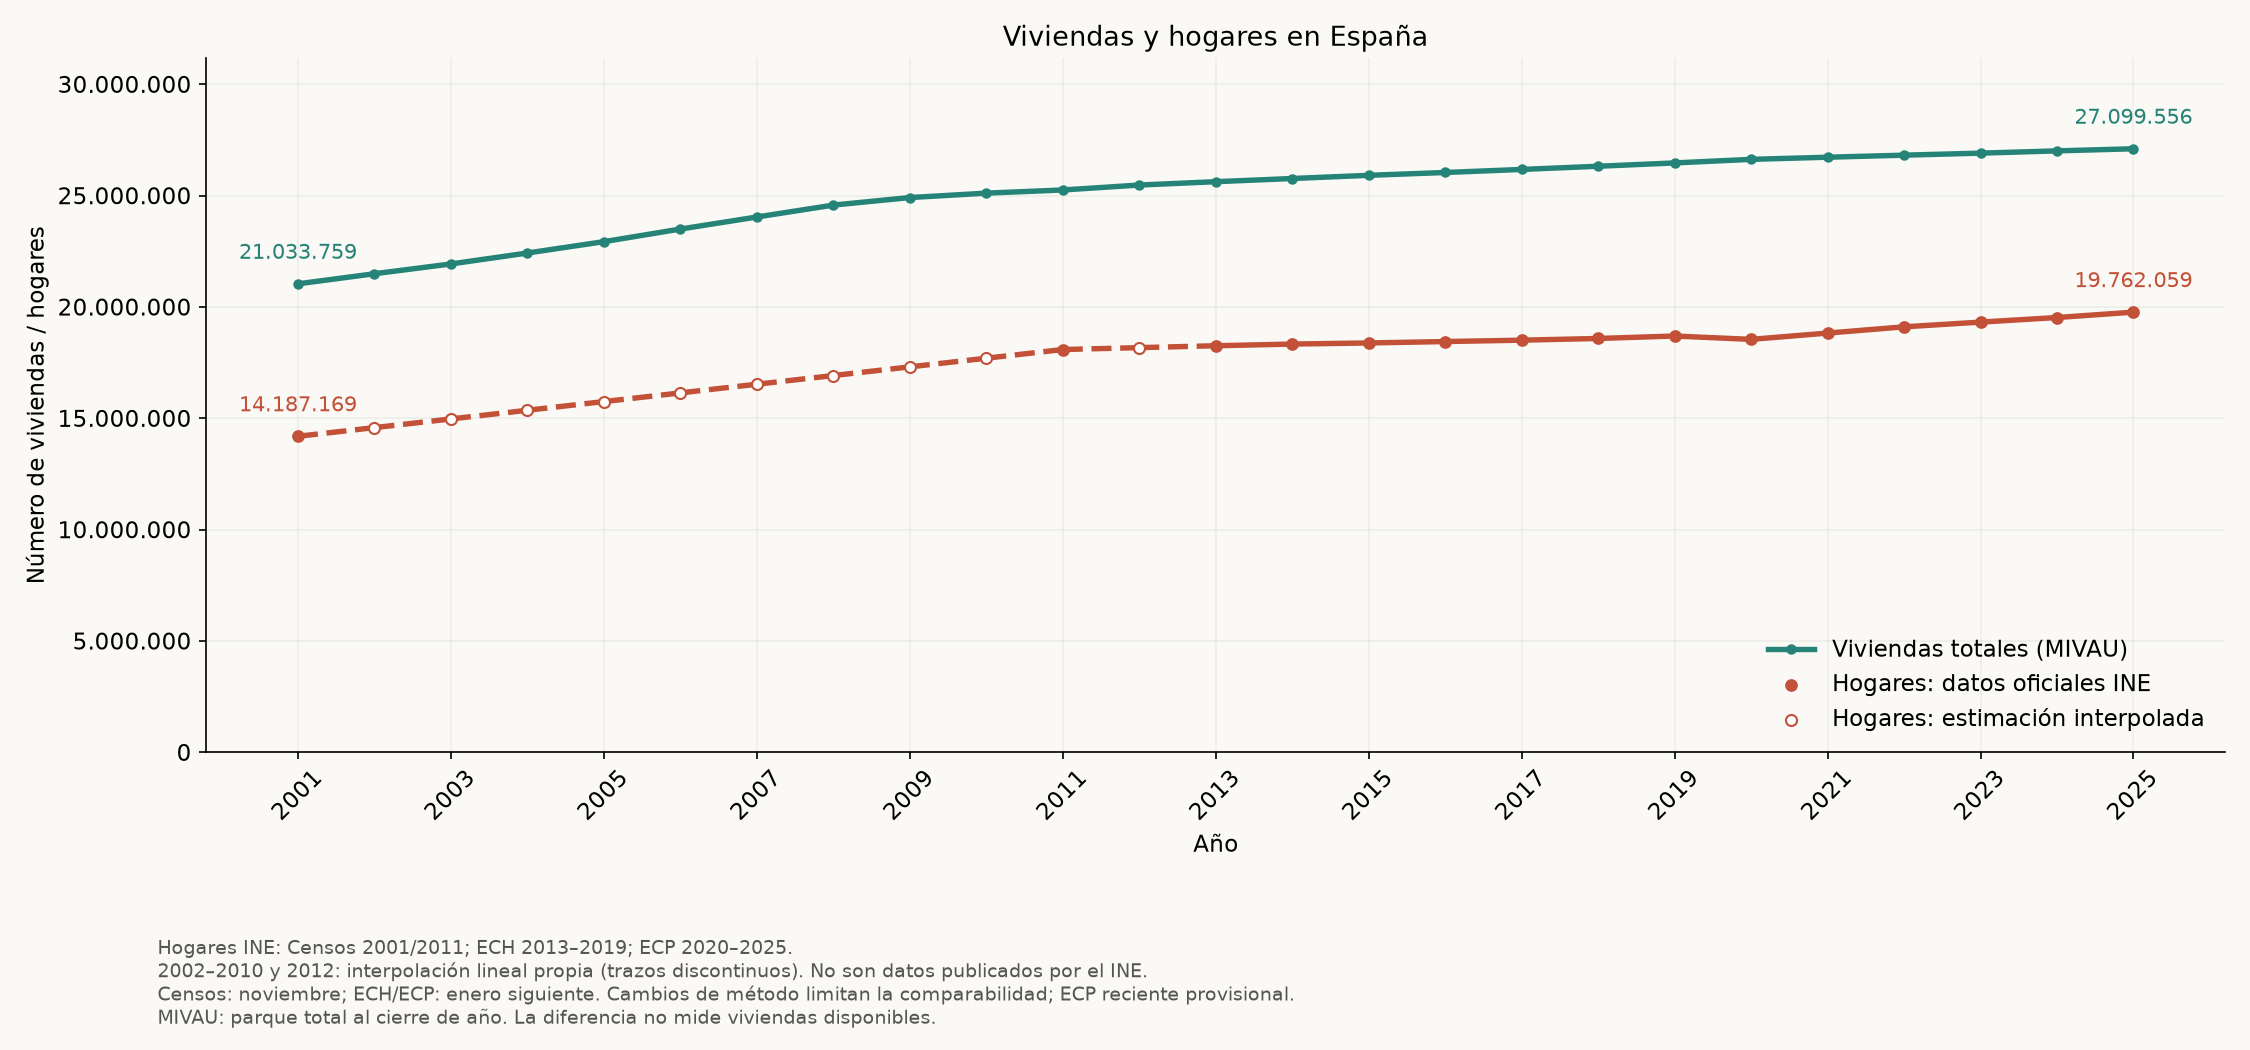

In [5]:
show('10_dwellings_households_totals')

## Hogares de una persona: cantidad y porcentaje

**Datos para todos los años de 2001 a 2025**, sin interpolar: Censo 2001 y **EPA, cuarto trimestre, 2002–2025**. Dos gráficas separadas muestran cantidad y porcentaje anual. Unipersonal significa una persona, no un progenitor con hijos.

Se toma la categoría **Total** del número de activos, evitando sumar subtotales, y las categorías **Total** y **Una persona** del tamaño del hogar. Los miles de hogares se convierten a hogares. Porcentaje = unipersonales / hogares totales de la misma fuente y trimestre × 100.

La EPA cubre los huecos, pero sus cambios metodológicos y de base poblacional afectan la comparación temporal. Censo de noviembre de 2001: punto separado, no equivalente a un cuarto trimestre EPA. Son estimaciones redondeadas; pueden diferir de ECH/ECP. Se cuentan hogares en viviendas familiares, no todas las viviendas del parque. No se interpolan datos ni se afirma una serie metodológicamente homogénea.

[INE EPA, tabla 65269](https://www.ine.es/jaxiT3/Tabla.htm?t=65269) · [Censo 2001, página 2](https://www.ine.es/prensa/np824.pdf). Originales y hashes guardados. Estas cifras no prueban preferencia por vivir solo ni cuantifican su efecto en precios.


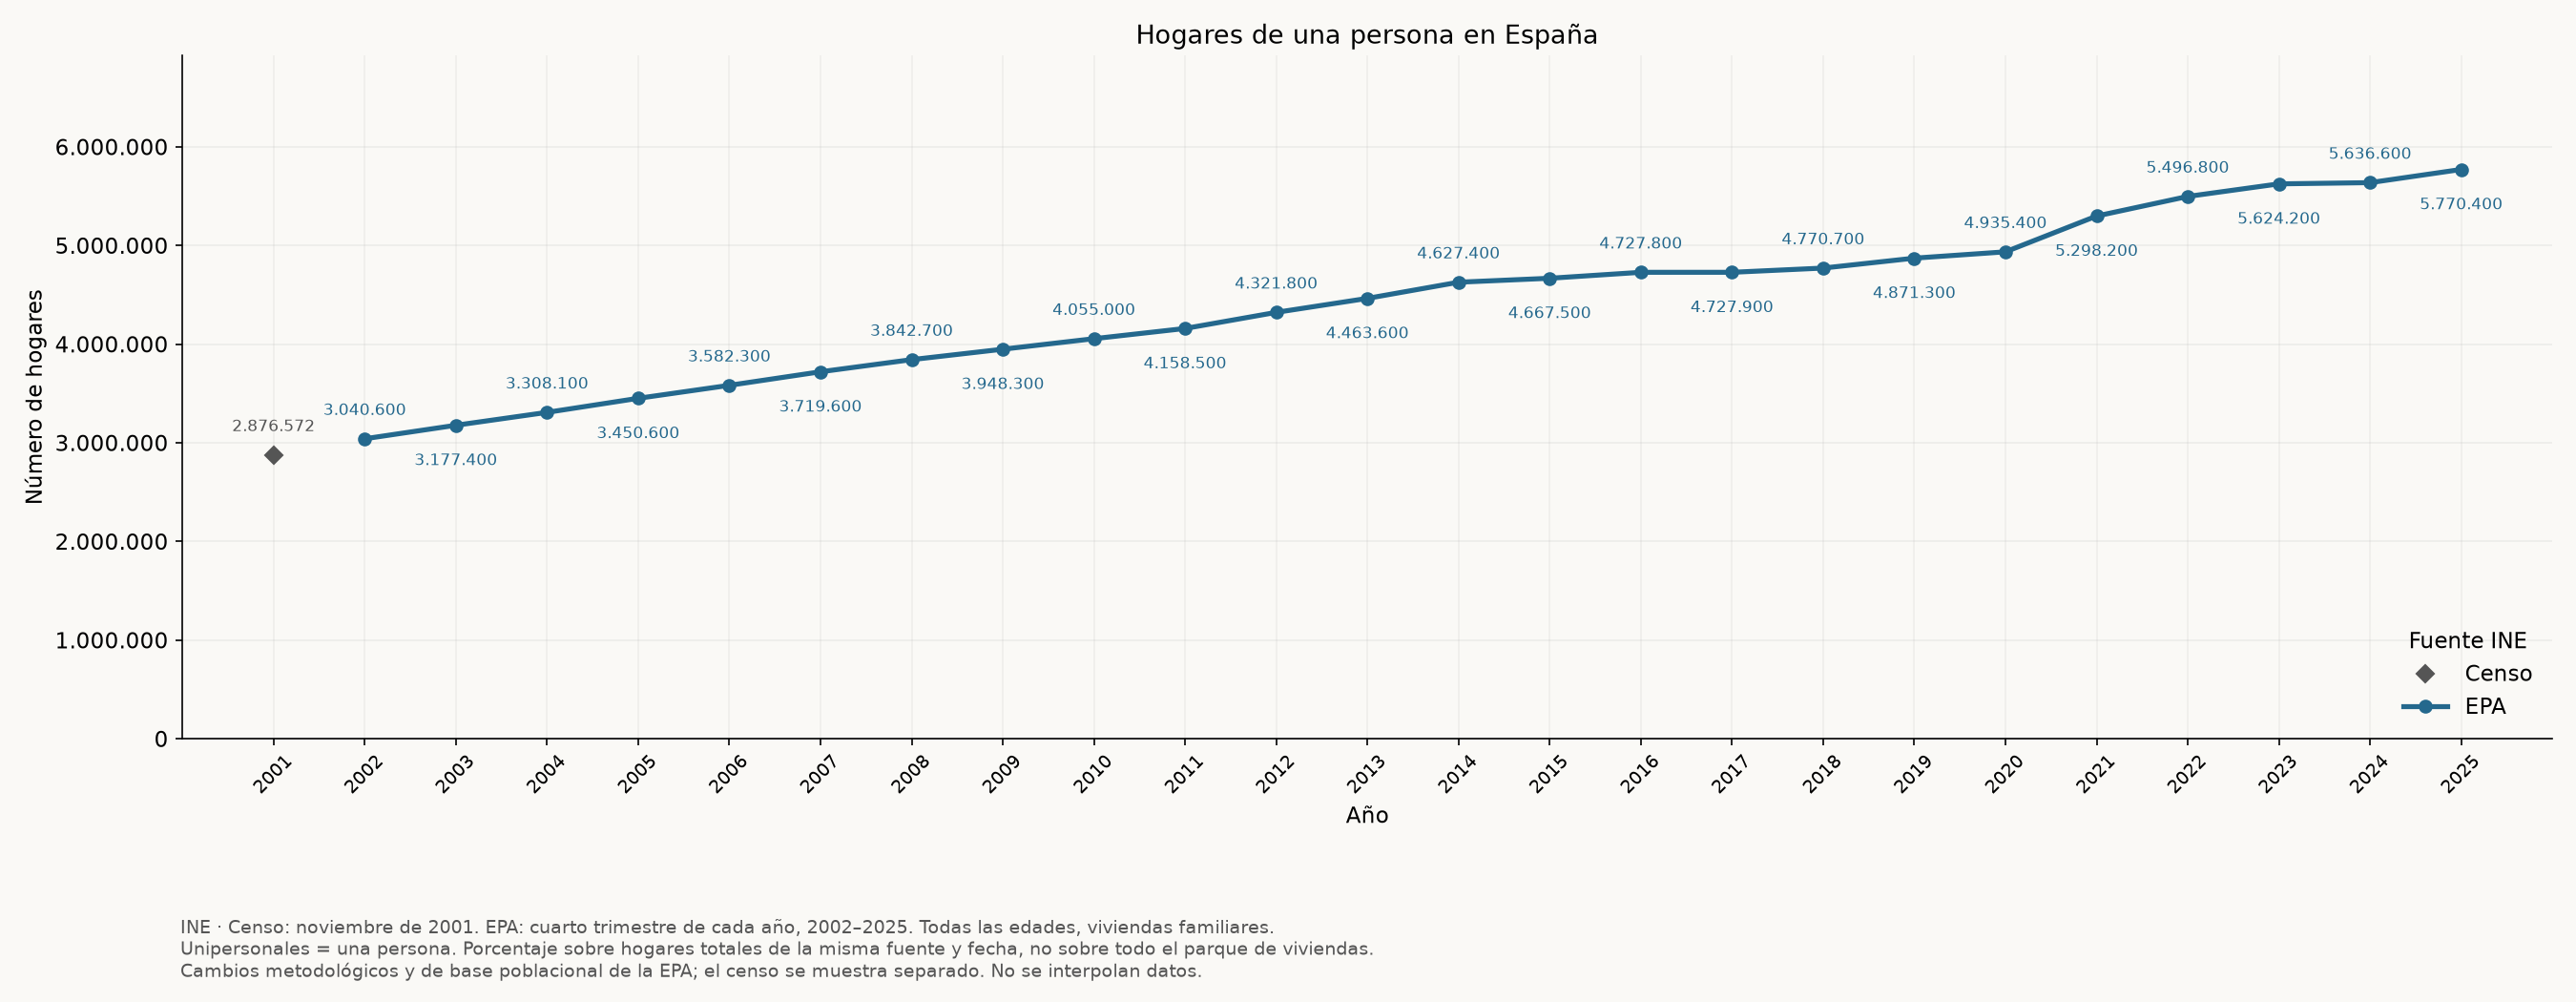

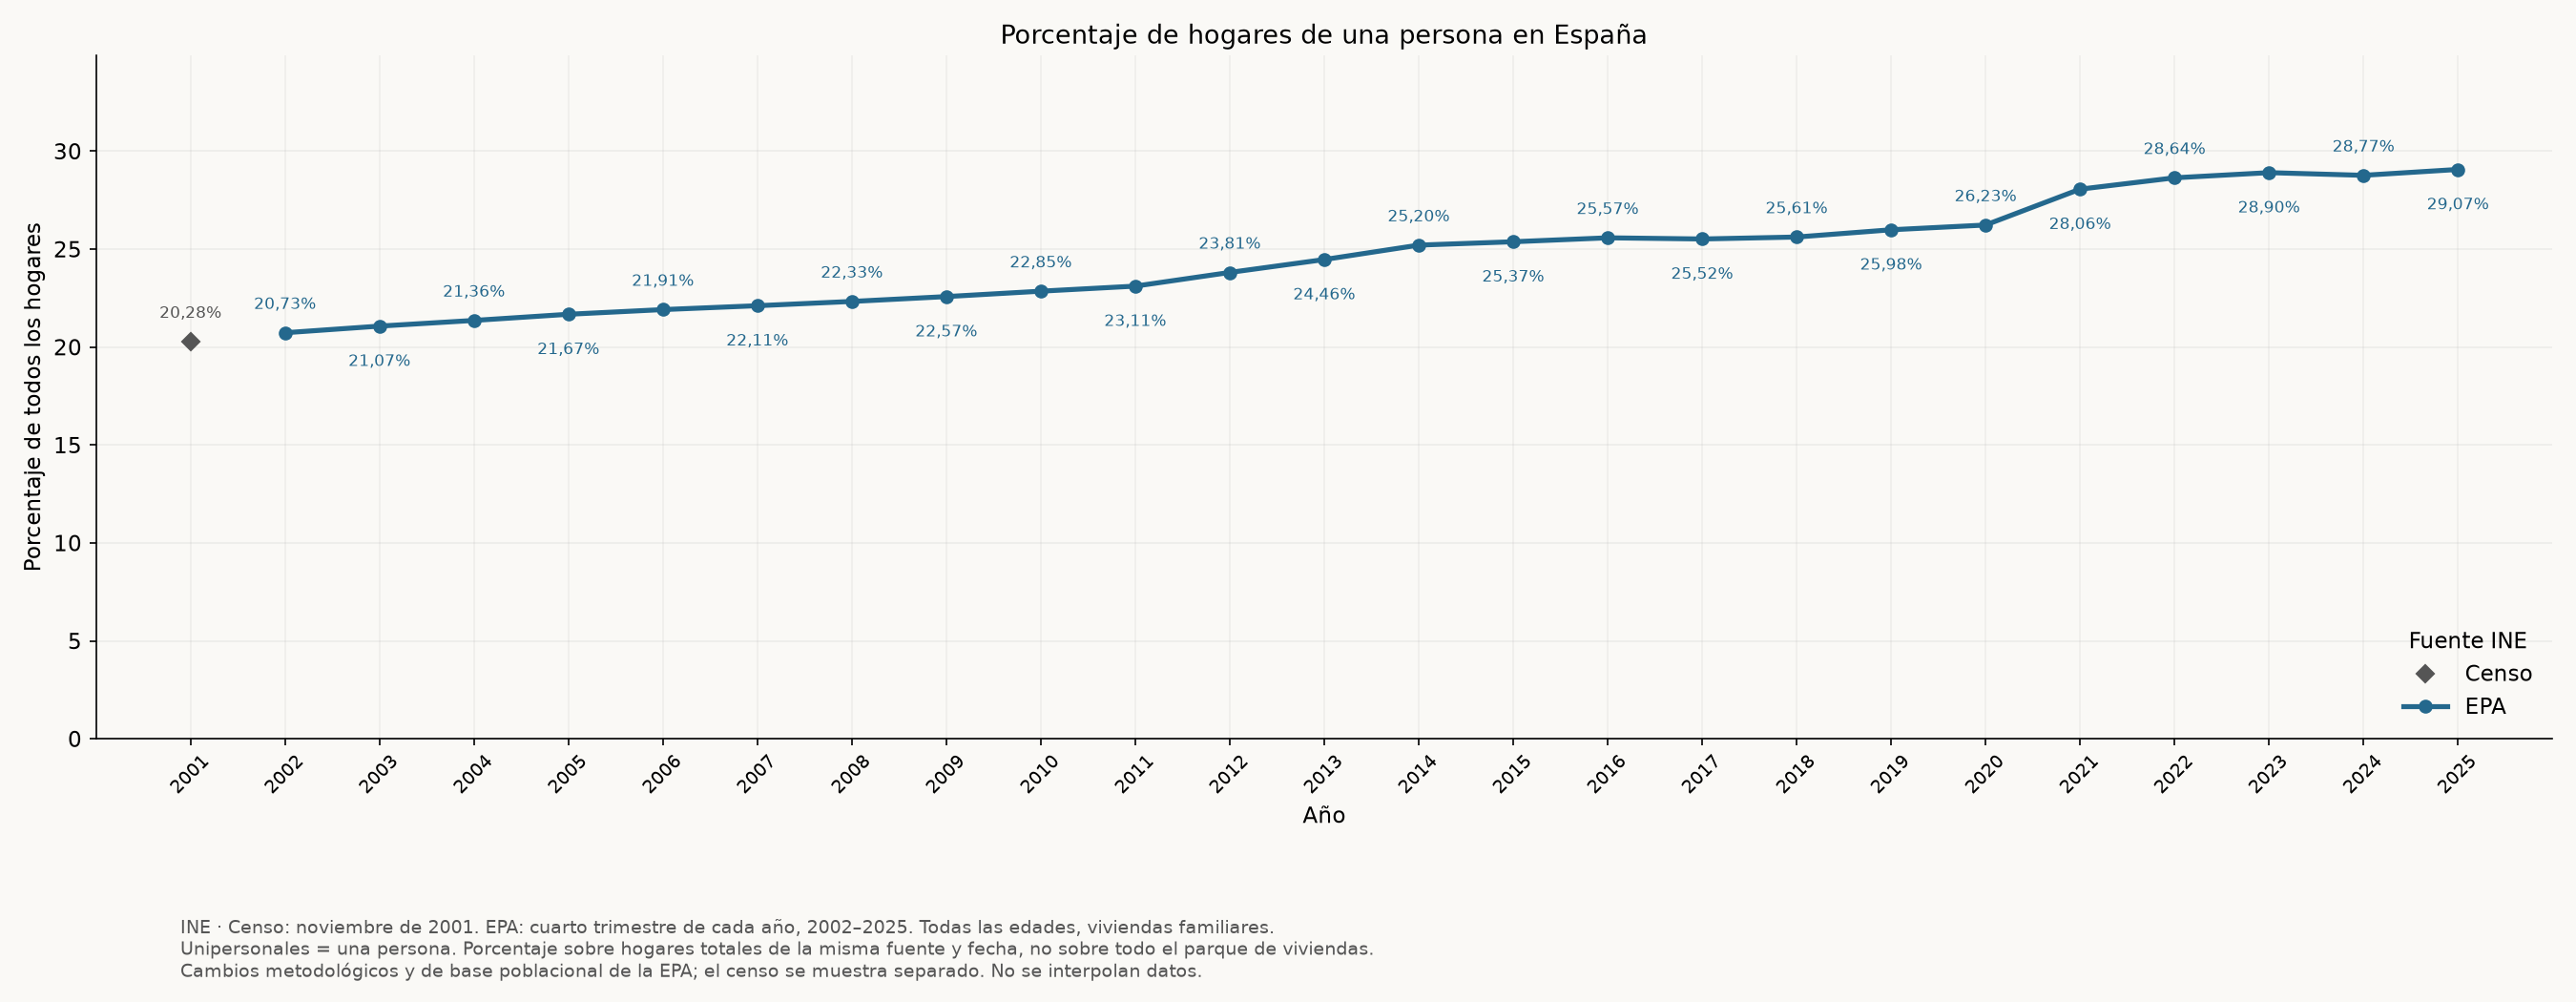

In [6]:
show('08_single_person_households', '09_single_person_households_share')

## Construcción de viviendas

Histórico anual **2000–2025**, en número de viviendas: iniciadas y terminadas, libres + protegidas. Tabla 1.2 del Boletín Anual 2013 del ministerio para 2000–2007 y snapshot mensual MIVAU desde 2008. Los cinco años comunes 2008–2012 coinciden exactamente en ambas medidas; cada ejecución lo comprueba.

Iniciadas no equivale a terminadas. Se conserva la definición ministerial, basada en visados y calificaciones de protección. No son compraventas ni hogares adicionales. **Nota de la fuente:** en 2000 el total publicado de terminadas es 415.258, mientras los subtotales publicados suman 416.258. Se conserva el total nacional del boletín y se documenta la discrepancia, sin corregirla silenciosamente.

[Fuente histórica, tabla 1.2, página 7](https://publicaciones.transportes.gob.es/downloadcustom/sample/1029). PDF, CSV y hashes conservados para reproducir sin red.


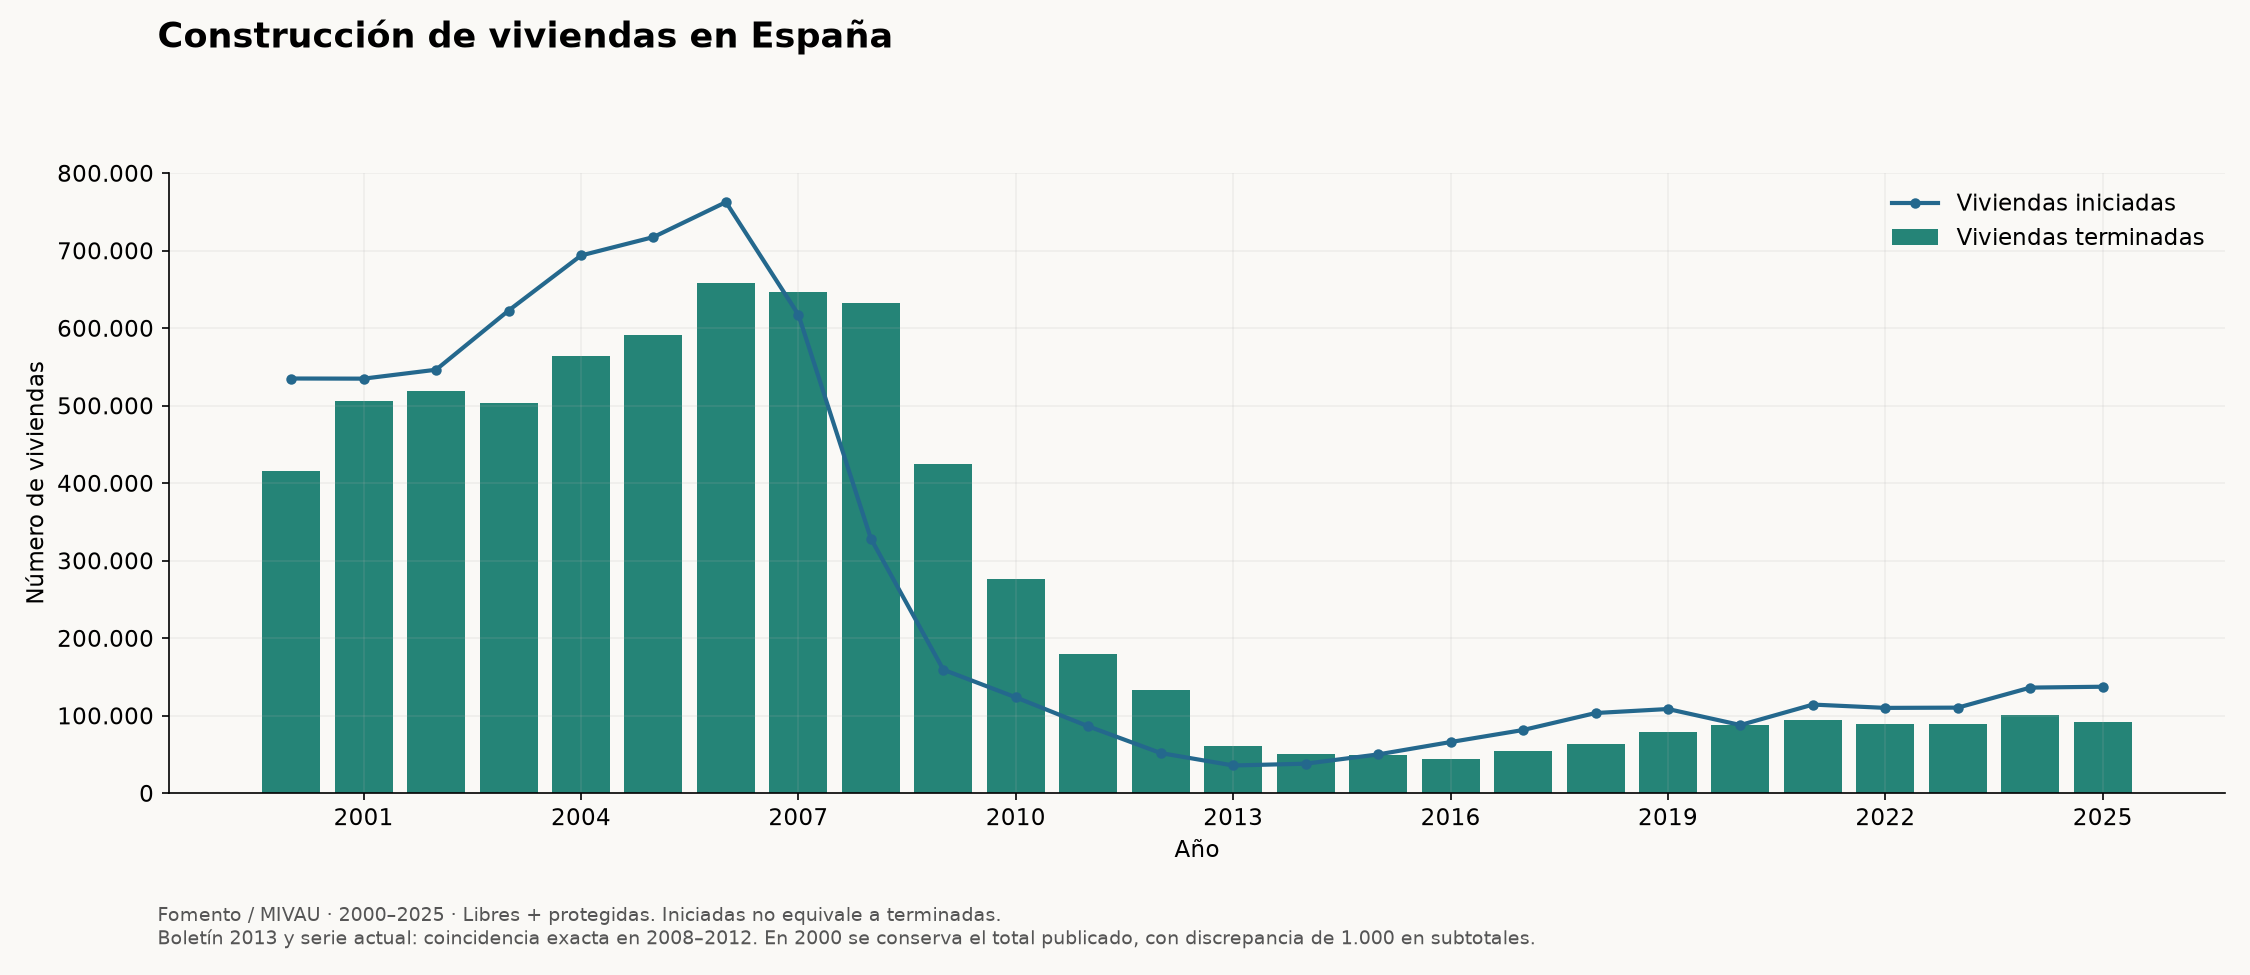

In [7]:
show('03_construction')

## Población por origen migratorio

Fuente: **INE, Encuesta Continua de Hogares**, tablas 02011 y 02003. **Todas las edades**, residentes en viviendas familiares, **2014–2020**, datos referidos al **1 de enero de cada año**. No se mezclan con stocks de cierre ni con Eurostat. Estas tablas no ofrecen datos posteriores a 2020.

**Origen inmigrante** = nacidos en el extranjero, independientemente de su nacionalidad, más nacidos en España con **ambos progenitores nacidos en el extranjero**. Incluye nacionalizados y niños; no se extiende el criterio a nietos. **Resto** = población total menos origen inmigrante identificado. Los casos nacidos aquí sin información suficiente de los padres quedan en el resto y se cuantifican por separado en el CSV; no se les atribuye origen español. Nacionalidad y origen son variables diferentes.

La tabla de hijos contiene personas con al menos un progenitor nacido fuera. Para obtener ambos padres nacidos fuera se resta de ese total quienes tienen madre o padre nacidos en España y quienes tienen madre o padre sin dato. Estos márgenes son excluyentes dentro de esa tabla. Se utilizan agregados publicados, sin tratar las celdas ausentes como ceros. Los datos son estimaciones en miles con un decimal; pasarlos a personas no aumenta su precisión.

[Tabla de población y origen de los padres](https://www.ine.es/jaxi/tabla.do?L=0&file=02011.px&path=/t20/p274/serie/def/p04/l0/&type=pcaxis) · [Tabla de hijos nacidos en España](https://www.ine.es/jaxi/tabla.do?L=0&file=02003.px&path=/t20/p274/serie/def/p04/l0/&type=pcaxis). Originales PC-Axis y hashes guardados para reproducir sin red.


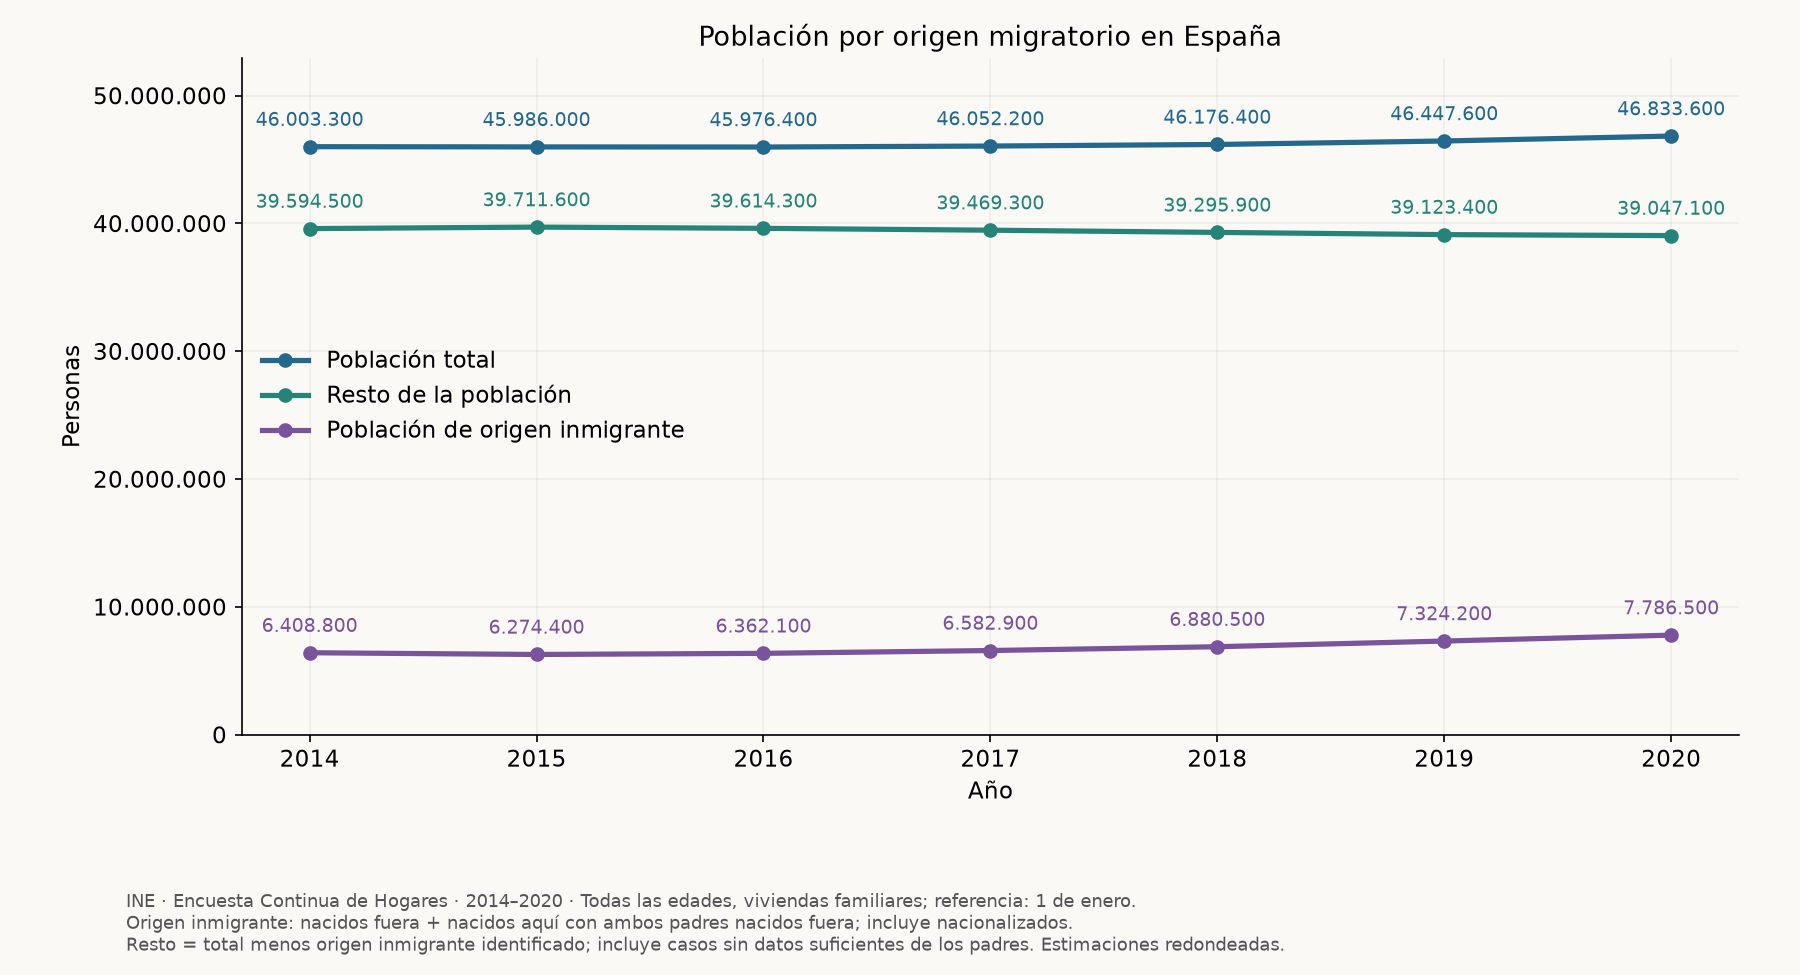

In [8]:
show('07_migration_background')

## Evolución de las llegadas de extranjeros por país de procedencia

Una sola gráfica con todos los años disponibles, **2008–2024**, y los **quince países con más llegadas acumuladas durante todo el periodo**. El grupo de países es fijo: no cambia cada año. La leyenda está ordenada por el total acumulado.

Cada línea representa un país y cada punto muestra las **llegadas de ese año**, en cifras absolutas. El ranking se calcula entre los países publicados individualmente por el INE; se excluyen continentes, totales y grupos de otros países.

**Procedencia = país de residencia anterior**, no necesariamente nacionalidad o nacimiento. Se cuentan movimientos migratorios de entrada de personas de nacionalidad extranjera, no residentes totales ni saldos. No aplica la definición familiar del apartado anterior.

Fuentes: [INE, tabla 24295](https://www.ine.es/jaxiT3/Tabla.htm?t=24295), 2008–2020, y [INE, tabla 69690](https://www.ine.es/jaxiT3/Tabla.htm?t=69690), 2021–2024. Se marca el cambio de estadística en 2021: limita la comparabilidad entre tramos. Sin predicciones; 2024 es el último año disponible en estas tablas.


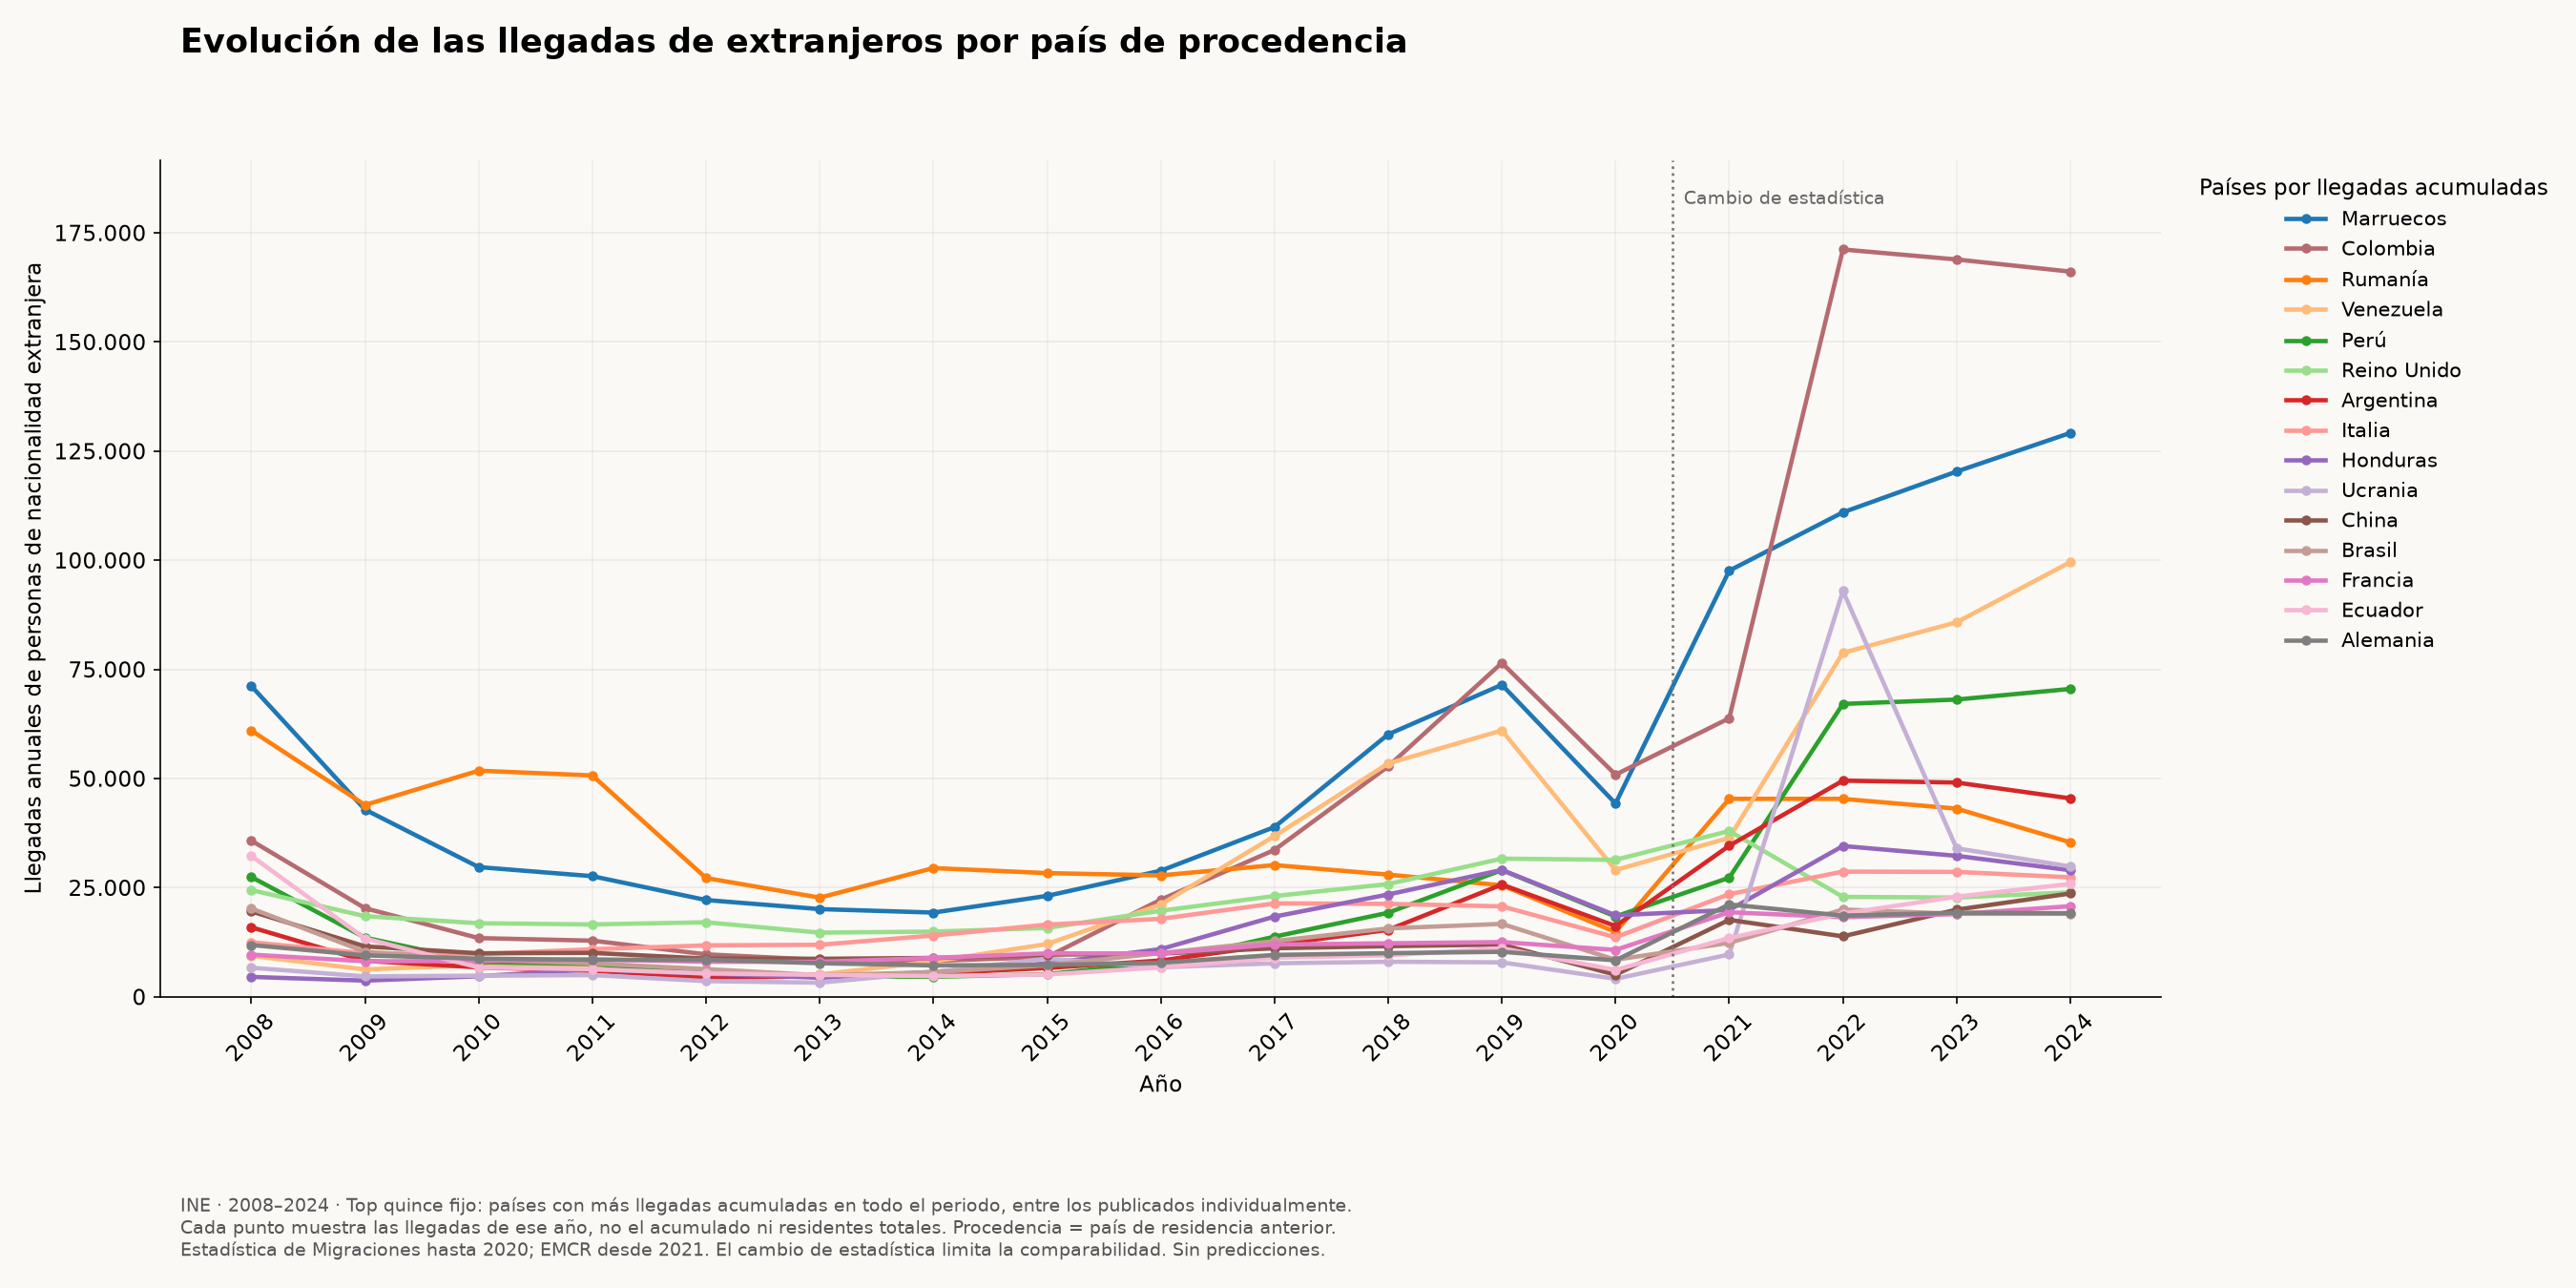

In [9]:
show('12_immigration_provenance')

## Diferencias territoriales

El total nacional no muestra si población, hogares y viviendas crecen en los mismos lugares. Comparamos las comunidades con el mismo periodo y escala, 2020–2025.

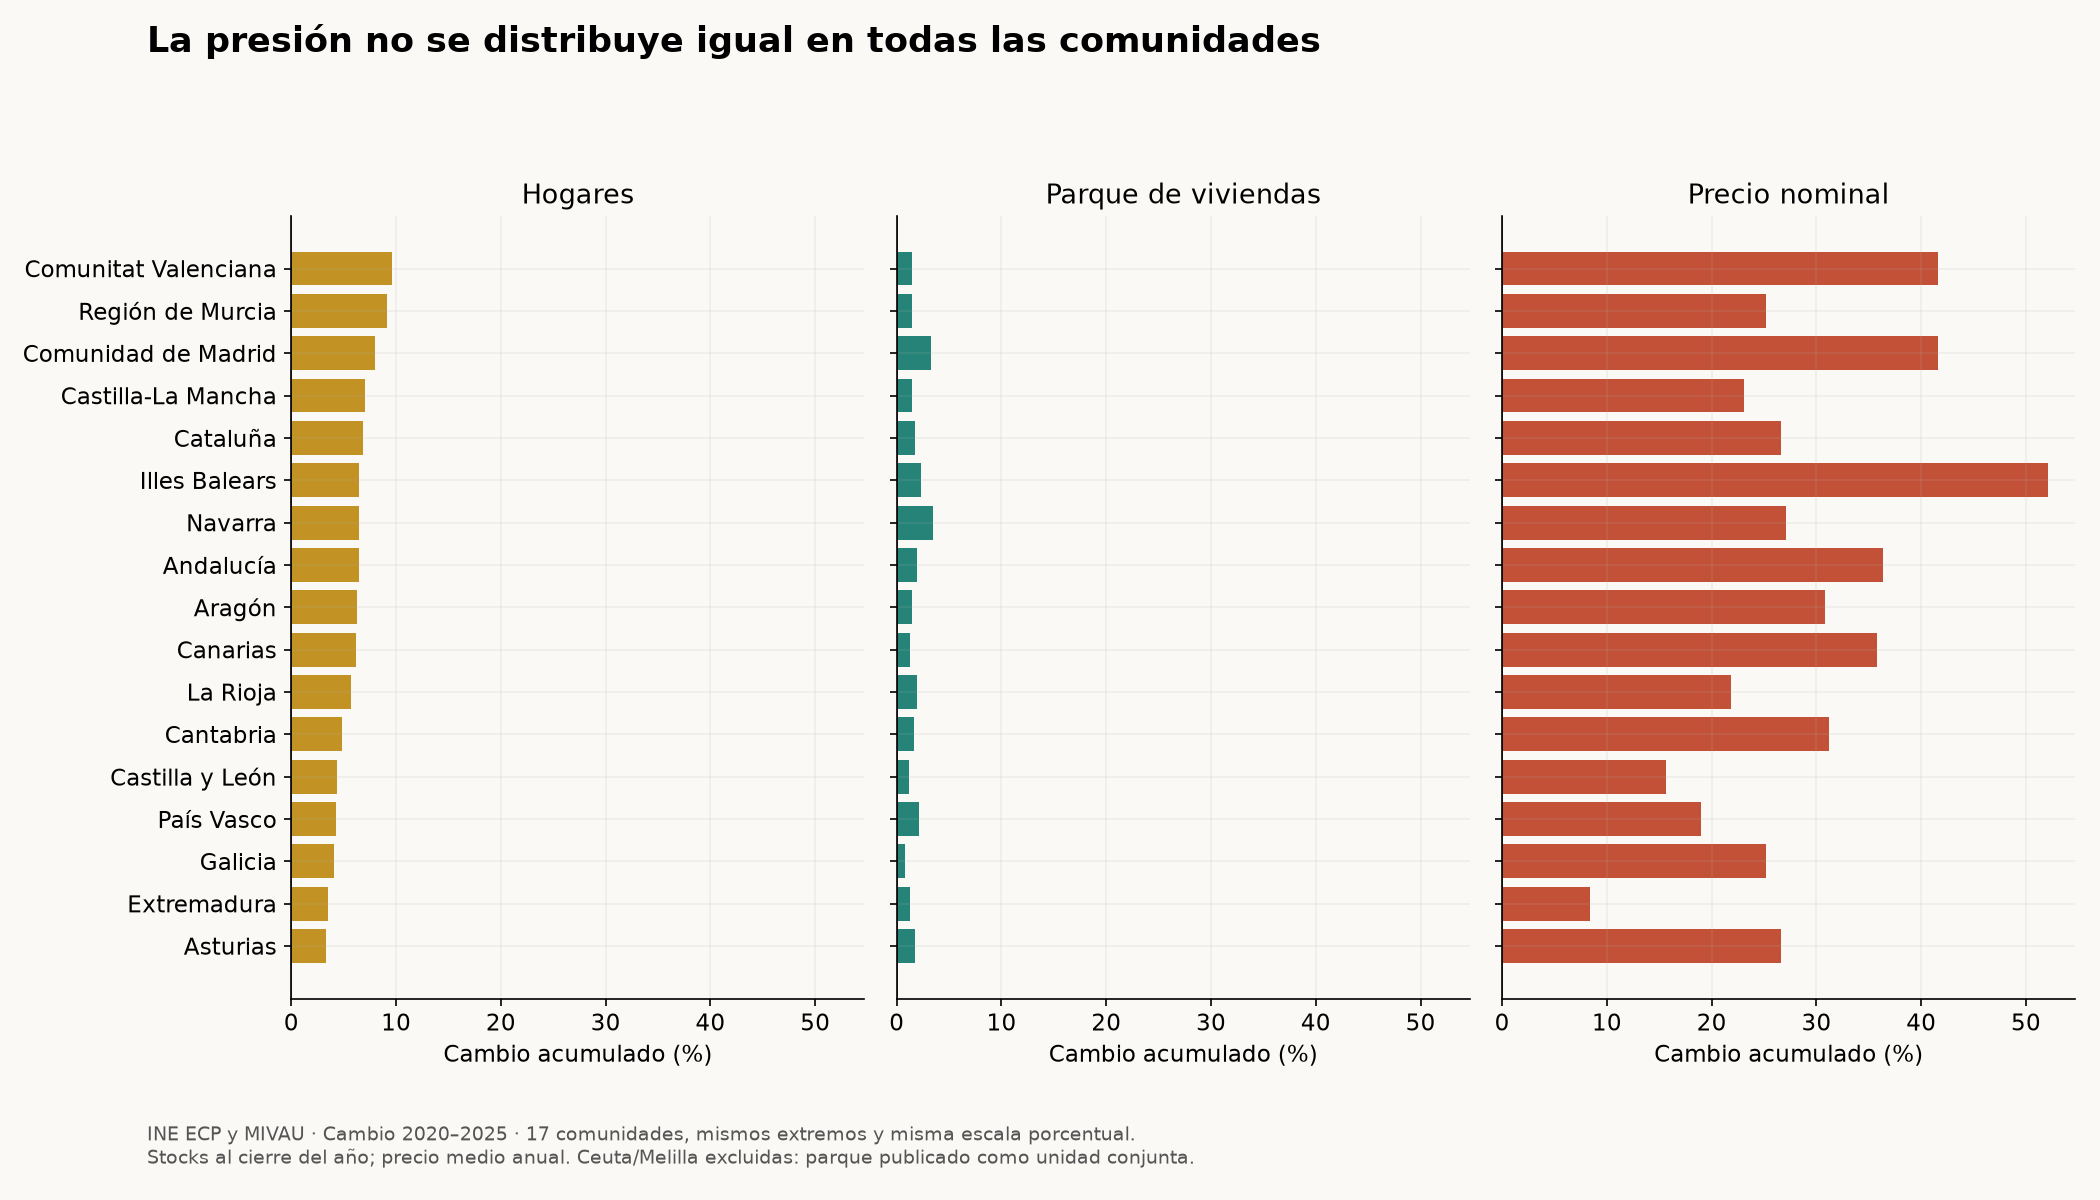

In [10]:
show("06_regional_comparison")

## Qué podemos concluir y qué falta

Población, hogares, parque y construcción son medidas distintas. Una vivienda no principal no equivale a una vivienda habitable disponible; una llegada no equivale a una persona residente distinta. Los hogares interpolados están señalados.

Estas gráficas describen tendencias; no identifican cuánto cambia el precio por inmigración ni por hogares unipersonales. Para evaluar esas explicaciones faltan datos locales de oferta disponible, alquileres, financiación y proyectos bloqueados.

Los siguientes bloques pendientes están en [el plan de trabajo](../docs/research_plan.md).

## Fuentes, fechas y reglas comunes

| Variable | Fuente | Uso en este bloque |
|---|---|---|
| Precio | MIVAU, snapshot del bloque 1 | Media de cuatro trimestres completos, 2000–2025; nominal |
| Población y adultos | INE ECP 56934 y 59583 | Cierre 2000–2025; 2025 provisional |
| Parque total | MIVAU VDP002_01 | 31 de diciembre, 2001–2025 |
| Viviendas iniciadas y terminadas | MIVAU VDP005_01 | Suma de 12 meses, libres + protegidas, 2000–2025 |
| Hogares nacionales y autonómicos | INE ECP 60135 y 60131 | Cierre 2020–2025; creación neta 2021–2025 |
| Lugar de nacimiento | INE ECP 79276 y 79273 | Cierre 2001–2025; 2025 provisional |
| Saldos y crecimiento demográfico | INE IDB 1416, 5227, 61769 y 5224 | Tasas por 1.000 habitantes, 2008–2024 |

**Alineación:** el cierre del año *t* usa la población y hogares del **1 de enero de t+1**. Una variación de hogares durante 2025 compara enero de 2026 con enero de 2025. El precio sigue siendo una media anual, no un stock de cierre.

Las series definitivas tienen prioridad; solo se añaden fechas posteriores de la publicación provisional. Los hogares ECP y las estimaciones MIVAU pueden revisarse. No se interpolan datos, no se introducen proyecciones y no se usa un segundo eje vertical. Los precios nominales no miden accesibilidad ni crecimiento real: la comparación con IPC está en el bloque 1.

El parque incluye viviendas ocupadas y no principales; **no es oferta disponible para comprar o alquilar**. Un adulto no equivale a un hogar, y un hogar observado no recoge toda la demanda latente de quienes no consiguen emanciparse.

Las fuentes adicionales, los periodos y las interpolaciones se describen junto a cada gráfica y en los archivos de procedencia de `data/snapshots/block02/`.